# 🐱🐶 Transfer Learning: Gatos vs Cachorros com MobileNetV2

**Desafio DIO — Treinamento de Redes Neurais com Transfer Learning**

Neste notebook aplicamos **Transfer Learning** para classificar imagens de **gatos** e **cachorros** usando o dataset público `cats_vs_dogs`. Em vez de treinar uma CNN do zero (o que exigiria muitos dados e horas de GPU), reaproveitamos os pesos da **MobileNetV2** pré-treinada no ImageNet e adaptamos a rede ao nosso problema.

O trabalho é dividido em duas fases:

| Fase | O que é treinado | Taxa de aprendizado | Objetivo |
|---|---|---|---|
| **1. Extração de características** | Apenas a "cabeça" de classificação | `1e-3` | Aprender a nova tarefa com a base congelada |
| **2. Fine-tuning** | Últimas camadas da base + cabeça | `1e-5` | Refinar os padrões visuais para gatos e cachorros |

> 💡 **Dica:** execute este notebook no **Google Colab** com GPU (`Ambiente de execução → Alterar tipo de ambiente de execução → GPU`). O tempo total fica em torno de 15 a 25 minutos com o dataset completo.

## 📑 Sumário

1. [Ambiente e dependências](#1)
2. [Download e exploração do dataset](#2)
3. [Pipeline de dados](#3)
4. [Fase 1 — Extração de características](#4)
5. [Fase 2 — Fine-tuning](#5)
6. [Avaliação no conjunto de teste](#6)
7. [Previsões em imagens do teste](#7)
8. [Grad-CAM: onde a rede está olhando?](#8)
9. [Salvando o modelo](#9)
10. [Conclusão](#10)

<a id="1"></a>
## ⚙️ 1. Ambiente e dependências

No Colab, o TensorFlow já vem instalado. Localmente, use o `requirements.txt` do repositório:

```bash
pip install -r requirements.txt
```

Também fixamos a semente aleatória para que o experimento seja o mais reprodutível possível.

In [1]:
import json
import os
import shutil
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_curve,
)

warnings.filterwarnings("ignore")

SEED = 42
tf.keras.utils.set_random_seed(SEED)

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    pass

print("TensorFlow:", tf.__version__)
print("GPUs disponíveis:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0


GPUs disponíveis: []


### Configurações do experimento

Os hiperparâmetros do treinamento ficam definidos na célula abaixo.

In [2]:
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

if QUICK_RUN:
    TRAIN_SAMPLES, VAL_SAMPLES = 2000, 1400
    EPOCHS_HEAD, EPOCHS_FINE = 4, 3
    FINE_TUNE_AT = -20
else:
    TRAIN_SAMPLES, VAL_SAMPLES = None, None
    EPOCHS_HEAD, EPOCHS_FINE = 10, 5
    FINE_TUNE_AT = -30

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

IMAGES_DIR = PROJECT_ROOT / "images"
MODELS_DIR = PROJECT_ROOT / "models"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("QUICK_RUN:", QUICK_RUN)
print("Imagens serão salvas em:", IMAGES_DIR)
print("Modelos serão salvos em:", MODELS_DIR)

QUICK_RUN: False
Imagens serão salvas em: C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\images
Modelos serão salvos em: C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\models


<a id="2"></a>
## 📥 2. Download e exploração do dataset

O **Cats vs Dogs** é um dataset clássico de classificação binária, publicado no [Kaggle](https://www.kaggle.com/c/dogs-vs-cats) e também catalogado no [TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/cats_vs_dogs):

- **25.000 imagens** coloridas de gatos e cachorros;
- **Duas classes**: `cat` (0) e `dog` (1), em proporções equilibradas;
- **Não possui split oficial** de treino/validação/teste;
- O zip oficial contém alguns arquivos com extensão `.jpg` que na verdade são **BMP, GIF ou PSD**, além de poucas imagens realmente corrompidas. Validamos cada arquivo decodificando-o e descartamos apenas os inválidos (9 arquivos), sobrando **24.991 imagens**.

O download (≈800 MB) é feito uma única vez com `tf.keras.utils.get_file` e fica em cache. Na primeira execução também extraímos o zip e validamos as imagens — tudo de forma automática e multiplataforma.

Em seguida, montamos os conjuntos manualmente com uma semente fixa:

- **80% treino** (19.992 imagens);
- **10% validação** (2.499 imagens);
- **10% teste** (2.500 imagens).

O conjunto de teste só é usado na avaliação final, nunca durante o treinamento.

In [3]:
DATA_URL = (
    "https://download.microsoft.com/download/3/E/1/"
    "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
)

# get_file baixa (ou reutiliza o cache) sem extrair, para controlarmos a extração.
zip_path = Path(
    tf.keras.utils.get_file("cats_vs_dogs.zip", DATA_URL, extract=False)
)
DATA_ROOT = zip_path.parent / "cats_vs_dogs_data"
DATA_DIR = DATA_ROOT / "PetImages"

if not DATA_DIR.exists():
    print("Extraindo o dataset (só na primeira execução)...")
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(DATA_ROOT)
else:
    print("Dataset já extraído — usando o cache.")

class_dirs = sorted(path for path in DATA_DIR.iterdir() if path.is_dir())
CLASS_NAMES = [path.name.lower() for path in class_dirs]

# Valida cada arquivo tentando decodificá-lo de fato. O zip oficial contém
# alguns arquivos com extensão .jpg que na verdade são BMP/GIF/PSD, além de
# poucas imagens corrompidas. Descartá-los aqui evita que o treino quebre no
# meio de uma época.
valid_paths, valid_labels = [], []
skipped = 0
processed = 0

for label, class_dir in enumerate(class_dirs):
    for path in sorted(class_dir.glob("*.jpg")):
        processed += 1
        raw = tf.io.read_file(str(path))
        try:
            tf.io.decode_image(raw, channels=3, expand_animations=False)
        except (tf.errors.InvalidArgumentError, ValueError):
            skipped += 1
            continue
        valid_paths.append(str(path))
        valid_labels.append(label)
        if processed % 5000 == 0:
            print(f"  {processed:,} arquivos verificados...", flush=True)

print(f"Imagens válidas:     {len(valid_paths):,}")
print(f"Imagens descartadas: {skipped:,}")
print("Classes:", CLASS_NAMES)
print("Distribuição:", dict(zip(CLASS_NAMES, np.bincount(valid_labels).tolist())))

Dataset já extraído — usando o cache.


  5,000 arquivos verificados...


  10,000 arquivos verificados...


  15,000 arquivos verificados...


  20,000 arquivos verificados...


  25,000 arquivos verificados...


Imagens válidas:     24,991
Imagens descartadas: 9
Classes: ['cat', 'dog']
Distribuição: {'cat': 12497, 'dog': 12494}


In [4]:
n_total = len(valid_paths)
order = np.random.default_rng(SEED).permutation(n_total)

n_train = int(0.8 * n_total)
n_val = int(0.1 * n_total)

train_idx = order[:n_train]
val_idx = order[n_train:n_train + n_val]
test_idx = order[n_train + n_val:]

if QUICK_RUN:
    train_idx = train_idx[:TRAIN_SAMPLES]
    val_idx = val_idx[:VAL_SAMPLES // 2]
    test_idx = test_idx[:VAL_SAMPLES // 2]


def load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label


def make_raw_dataset(indices, training=False):
    paths = [valid_paths[i] for i in indices]
    labels = [valid_labels[i] for i in indices]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE)


ds_train_raw = make_raw_dataset(train_idx, training=True)
ds_val_raw = make_raw_dataset(val_idx)
ds_test_raw = make_raw_dataset(test_idx)


def cardinality(ds):
    value = tf.data.experimental.cardinality(ds).numpy()
    return int(value) if value > 0 else "desconhecido"


print(f"Treino:    {cardinality(ds_train_raw)} imagens")
print(f"Validação: {cardinality(ds_val_raw)} imagens")
print(f"Teste:     {cardinality(ds_test_raw)} imagens")
print("Classes:", CLASS_NAMES)
print("Diretório:", DATA_DIR)

Treino:    19992 imagens
Validação: 2499 imagens
Teste:     2500 imagens
Classes: ['cat', 'dog']
Diretório: C:\Users\Will\.keras\datasets\cats_vs_dogs_data\PetImages


### Amostras do dataset

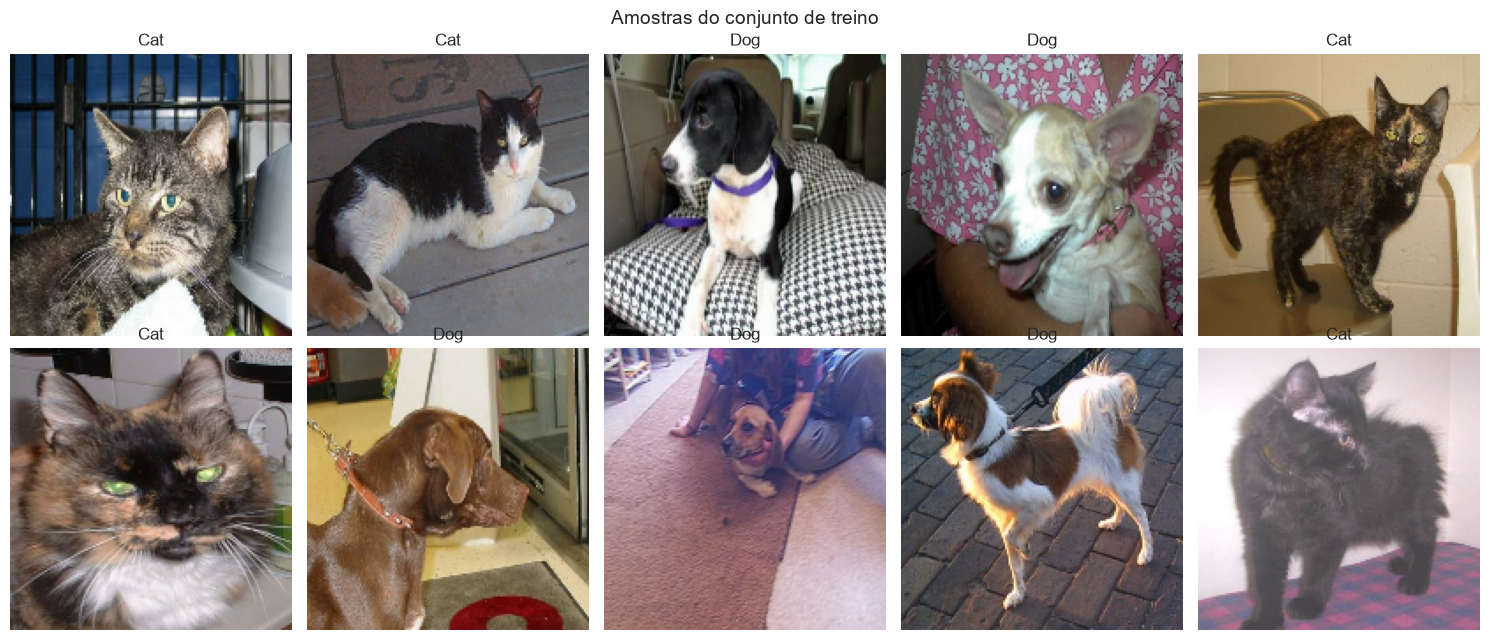

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))

for ax, (image, label) in zip(axes.ravel(), ds_train_raw.take(10)):
    ax.imshow(image.numpy().astype("uint8"))
    ax.set_title(CLASS_NAMES[int(label)].capitalize(), fontsize=12)
    ax.axis("off")

fig.suptitle("Amostras do conjunto de treino", fontsize=14)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "amostras_dataset.png", dpi=150, bbox_inches="tight")
plt.show()

### Distribuição das classes

O dataset é praticamente balanceado. Abaixo verificamos isso em uma amostra do treino:

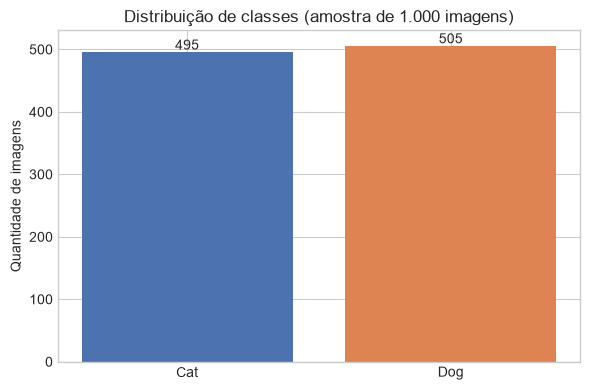

Contagem na amostra: {'cat': 495, 'dog': 505}


In [6]:
sample_labels = np.array([int(label) for _, label in ds_train_raw.take(1000)])
counts = np.bincount(sample_labels, minlength=len(CLASS_NAMES))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([c.capitalize() for c in CLASS_NAMES], counts, color=["#4C72B0", "#DD8452"])
ax.bar_label(bars)
ax.set_title("Distribuição de classes (amostra de 1.000 imagens)")
ax.set_ylabel("Quantidade de imagens")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "distribuicao_classes.png", dpi=150, bbox_inches="tight")
plt.show()

print("Contagem na amostra:", dict(zip(CLASS_NAMES, counts.tolist())))

<a id="3"></a>
## 🔄 3. Pipeline de dados

Cada imagem passa pelas seguintes etapas:

1. **Redimensionamento** para `160 × 160` (tamanho de entrada da MobileNetV2 usada aqui);
2. **Pré-processamento** com `preprocess_input` da MobileNetV2, que escala os pixels de `[0, 255]` para `[-1, 1]`;
3. **Data augmentation** (apenas no treino): espelhamento horizontal, variação de brilho, contraste e saturação. Isso reduz overfitting e melhora a generalização;
4. **Batching** e `prefetch`, para alimentar a GPU sem gargalos.

O pipeline usa `tf.data`, que é a forma recomendada de carregar dados em escala no TensorFlow.

In [7]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


def prepare(image, label):
    '''Normaliza a imagem para a MobileNetV2 (pixels em [0, 255]).'''
    return preprocess_input(image), label


def augment(image, label):
    '''Aplicações aleatórias de augmentation (somente no treino).'''
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.image.random_saturation(image, lower=0.9, upper=1.1)
    return image, label


def build_pipeline(ds, training=False):
    ds = ds.map(prepare, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


ds_train = build_pipeline(ds_train_raw, training=True)
ds_val = build_pipeline(ds_val_raw, training=False)
ds_test = build_pipeline(ds_test_raw, training=False)

images, labels = next(iter(ds_train))
print("Shape do lote:", images.shape)
print("Shape dos rótulos:", labels.shape)
print(f"Faixa de pixels: {float(tf.reduce_min(images)):.2f} a {float(tf.reduce_max(images)):.2f}")

Shape do lote: (32, 160, 160, 3)
Shape dos rótulos: (32,)
Faixa de pixels: -1.11 a 1.19


<a id="4"></a>
## 🧠 4. Fase 1 — Extração de características

Nesta primeira fase:

- Carregamos a **MobileNetV2** com pesos do **ImageNet** e removemos a camada de classificação original (`include_top=False`);
- **Congelamos** todos os pesos da base (`base_model.trainable = False`);
- Adicionamos uma nova cabeça: `GlobalAveragePooling2D → Dropout(0.2) → Dense(1, sigmoid)`;
- Treinamos apenas essa cabeça. Assim, a rede aprende a mapear as características já existentes (bordas, texturas, formas) para "gato" ou "cachorro".

A MobileNetV2 foi escolhida por ser leve (~2,2 milhões de parâmetros na base) e rápida, ideal para Colab e para dispositivos com poucos recursos.

In [8]:
from tensorflow.keras import callbacks, layers, models, optimizers


def build_model():
    base = tf.keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
    )
    base.trainable = False

    inputs = layers.Input(shape=(*IMG_SIZE, 3), name="imagem")
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.2, name="dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="dense")(x)

    return models.Model(inputs, outputs, name="cats_vs_dogs_mobilenetv2"), base


model, base_model = build_model()

trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
total_params = int(sum(np.prod(w.shape) for w in model.weights))
print(f"Parâmetros treináveis: {trainable_params:,}")
print(f"Parâmetros totais:     {total_params:,}")
print(f"Base congelada:        {not base_model.trainable}")

Parâmetros treináveis: 1,281
Parâmetros totais:     2,259,265
Base congelada:        True


In [9]:
METRICS = [
    "accuracy",
    tf.keras.metrics.Precision(name="precision"),
    tf.keras.metrics.Recall(name="recall"),
    tf.keras.metrics.AUC(name="auc"),
]


def compile_model(learning_rate):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=METRICS,
    )


def make_callbacks(checkpoint_name, patience):
    return [
        callbacks.ModelCheckpoint(
            filepath=str(MODELS_DIR / checkpoint_name),
            monitor="val_auc",
            mode="max",
            save_best_only=True,
            verbose=1,
        ),
        callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=patience,
            restore_best_weights=True,
            verbose=1,
        ),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1,
        ),
    ]


compile_model(learning_rate=1e-3)
model.summary()

Model: "cats_vs_dogs_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
history_head = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS_HEAD,
    callbacks=make_callbacks("fase1_cabeca.keras", patience=3),
)

Epoch 1/10


  1/625 ━━━━━━━━━━━━━━━━━━━━ 3:48:05 22s/step - accuracy: 0.5312 - auc: 0.5238 - loss: 0.8624 - precision: 0.3333 - recall: 0.0714

  2/625 ━━━━━━━━━━━━━━━━━━━━ 9:47 944ms/step - accuracy: 0.4219 - auc: 0.6138 - loss: 0.9714 - precision: 0.6250 - recall: 0.1282 

  3/625 ━━━━━━━━━━━━━━━━━━━━ 9:46 943ms/step - accuracy: 0.5104 - auc: 0.6244 - loss: 0.8623 - precision: 0.6429 - recall: 0.1765

  4/625 ━━━━━━━━━━━━━━━━━━━━ 9:42 938ms/step - accuracy: 0.5781 - auc: 0.6255 - loss: 0.7834 - precision: 0.7200 - recall: 0.2769

  5/625 ━━━━━━━━━━━━━━━━━━━━ 9:39 934ms/step - accuracy: 0.6000 - auc: 0.6491 - loss: 0.7457 - precision: 0.7273 - recall: 0.3038

... (2,506 outputs left out)


Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.


625/625 ━━━━━━━━━━━━━━━━━━━━ 605s 969ms/step - accuracy: 0.9797 - auc: 0.9974 - loss: 0.0551 - precision: 0.9781 - recall: 0.9812 - val_accuracy: 0.9868 - val_auc: 0.9978 - val_loss: 0.0419 - val_precision: 0.9833 - val_recall: 0.9904 - learning_rate: 0.0010


Epoch 4: early stopping


Restoring model weights from the end of the best epoch: 1.


### Curvas de treinamento

A função abaixo junta as curvas das duas fases para comparar o efeito do fine-tuning.

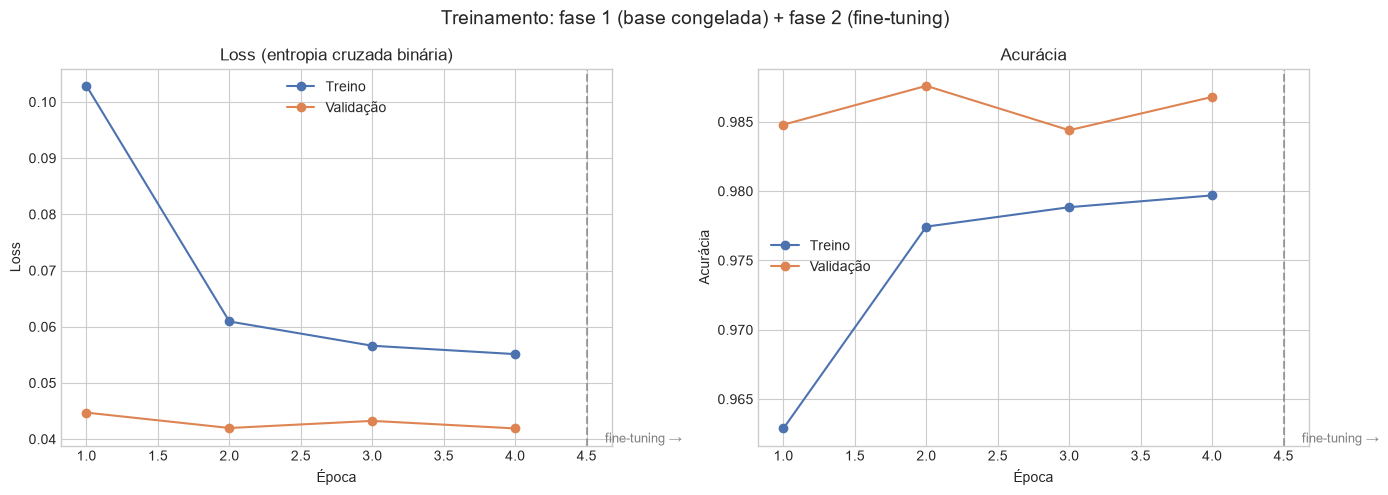

In [11]:
def plot_training_curves(histories, filename):
    def concat(key):
        return np.concatenate([np.asarray(h.history[key]) for h in histories])

    loss, val_loss = concat("loss"), concat("val_loss")
    acc, val_acc = concat("accuracy"), concat("val_accuracy")
    epochs = np.arange(1, len(loss) + 1)
    phase2_start = len(histories[0].history["loss"]) + 0.5

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, loss, marker="o", label="Treino", color="#4C72B0")
    axes[0].plot(epochs, val_loss, marker="o", label="Validação", color="#DD8452")
    axes[0].set_title("Loss (entropia cruzada binária)")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Loss")

    axes[1].plot(epochs, acc, marker="o", label="Treino", color="#4C72B0")
    axes[1].plot(epochs, val_acc, marker="o", label="Validação", color="#DD8452")
    axes[1].set_title("Acurácia")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Acurácia")

    for ax in axes:
        ax.axvline(phase2_start, color="gray", linestyle="--", alpha=0.7)
        ax.text(phase2_start + 0.1, ax.get_ylim()[0], " fine-tuning →", va="bottom", fontsize=9, color="gray")
        ax.legend()

    fig.suptitle("Treinamento: fase 1 (base congelada) + fase 2 (fine-tuning)", fontsize=14)
    fig.tight_layout()
    fig.savefig(IMAGES_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_training_curves([history_head], "curvas_fase1.png")

<a id="5"></a>
## 🔧 5. Fase 2 — Fine-tuning

Com a cabeça já treinada, descongelamos as **últimas 30 camadas** da MobileNetV2 e continuamos o treinamento com uma taxa de aprendizado bem menor (`1e-5`).

Por que isso funciona?

- As primeiras camadas da CNN detectam bordas e cores genéricas — úteis para qualquer imagem;
- As últimas camadas detectam padrões mais específicos — que vale a pena ajustar para o nosso domínio;
- Uma taxa de aprendizado baixa evita "destruir" os pesos pré-treinados com atualizações agressivas.

As camadas de **Batch Normalization ficam congeladas**: atualizá-las com lotes pequenos costuma desestabilizar o treinamento.

In [12]:
base_model.trainable = True

fine_tune_at = len(base_model.layers) + FINE_TUNE_AT if FINE_TUNE_AT < 0 else FINE_TUNE_AT
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"Camadas descongeladas a partir do índice: {fine_tune_at} de {len(base_model.layers)}")
print(f"Parâmetros treináveis agora: {trainable_params:,}")

compile_model(learning_rate=1e-5)

Camadas descongeladas a partir do índice: 124 de 154
Parâmetros treináveis agora: 1,512,001


In [13]:
history_fine = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS_FINE,
    callbacks=make_callbacks("fase2_finetuning.keras", patience=2),
)

Epoch 1/5


  1/625 ━━━━━━━━━━━━━━━━━━━━ 2:40:05 15s/step - accuracy: 0.9688 - auc: 0.9978 - loss: 0.0663 - precision: 0.9827 - recall: 0.9905

  2/625 ━━━━━━━━━━━━━━━━━━━━ 5:42 550ms/step - accuracy: 0.9531 - auc: 0.9978 - loss: 0.0918 - precision: 0.9814 - recall: 0.9906 

  3/625 ━━━━━━━━━━━━━━━━━━━━ 5:57 574ms/step - accuracy: 0.9688 - auc: 0.9978 - loss: 0.0666 - precision: 0.9816 - recall: 0.9907

  4/625 ━━━━━━━━━━━━━━━━━━━━ 5:58 577ms/step - accuracy: 0.9531 - auc: 0.9978 - loss: 0.0846 - precision: 0.9803 - recall: 0.9900

  5/625 ━━━━━━━━━━━━━━━━━━━━ 5:52 568ms/step - accuracy: 0.9500 - auc: 0.9978 - loss: 0.0918 - precision: 0.9790 - recall: 0.9901

... (3,136 outputs left out)


Epoch 5: val_auc did not improve from 0.99862



Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.


625/625 ━━━━━━━━━━━━━━━━━━━━ 654s 1s/step - accuracy: 0.9934 - auc: 0.9995 - loss: 0.0213 - precision: 0.9930 - recall: 0.9938 - val_accuracy: 0.9880 - val_auc: 0.9983 - val_loss: 0.0354 - val_precision: 0.9927 - val_recall: 0.9832 - learning_rate: 1.0000e-05


Restoring model weights from the end of the best epoch: 4.


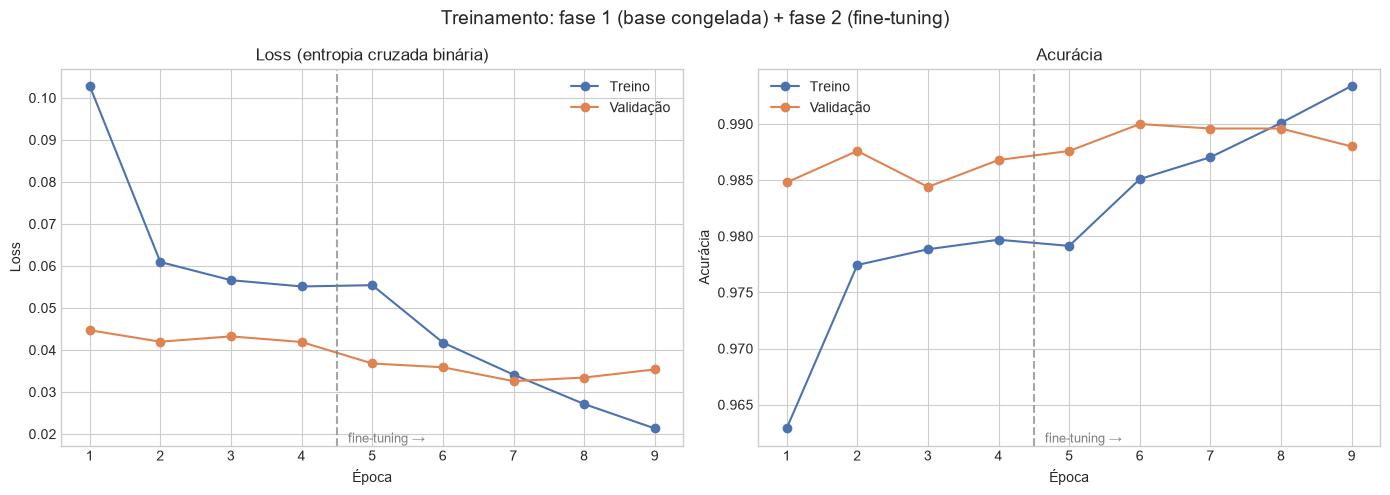

In [14]:
plot_training_curves([history_head, history_fine], "curvas_treinamento.png")

<a id="6"></a>
## 📊 6. Avaliação no conjunto de teste

Agora usamos o conjunto de **teste** (nunca visto durante o treino) para medir o desempenho real do modelo. Além da acurácia, olhamos para:

- **Precisão**: dos que o modelo disse "cachorro", quantos realmente eram?
- **Recall**: de todos os cachorros reais, quantos o modelo encontrou?
- **F1-score**: média harmônica entre precisão e recall;
- **AUC-ROC**: capacidade de separar as duas classes em todos os limiares.

In [15]:
test_metrics = model.evaluate(ds_test, verbose=0, return_dict=True)

for name, value in test_metrics.items():
    print(f"{name:>10}: {value:.4f}")

with open(MODELS_DIR / "metricas_teste.json", "w", encoding="utf-8") as f:
    json.dump({k: float(v) for k, v in test_metrics.items()}, f, indent=2, ensure_ascii=False)

  accuracy: 0.9836
       auc: 0.9991
      loss: 0.0426
 precision: 0.9779
    recall: 0.9907


In [16]:
y_true = np.concatenate([np.asarray(y) for _, y in ds_test]).ravel().astype(int)
y_prob = model.predict(ds_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

report = classification_report(
    y_true,
    y_pred,
    target_names=[c.capitalize() for c in CLASS_NAMES],
    digits=4,
)
print(report)

with open(MODELS_DIR / "relatorio_classificacao.txt", "w", encoding="utf-8") as f:
    f.write(report)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=[c.capitalize() for c in CLASS_NAMES],
    output_dict=True,
    digits=4,
)
with open(MODELS_DIR / "relatorio_classificacao.json", "w", encoding="utf-8") as f:
    json.dump(report_dict, f, indent=2, ensure_ascii=False)

resumo = {
    "quick_run": QUICK_RUN,
    "arquitetura": "MobileNetV2",
    "img_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "n_treino": cardinality(ds_train_raw),
    "n_validacao": cardinality(ds_val_raw),
    "n_teste": int(len(y_true)),
    "epocas_fase1": len(history_head.history["loss"]),
    "epocas_fase2": len(history_fine.history["loss"]),
}
with open(MODELS_DIR / "resumo_execucao.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, indent=2, ensure_ascii=False)

print(json.dumps(resumo, indent=2, ensure_ascii=False))

              precision    recall  f1-score   support

         Cat     0.9899    0.9760    0.9829      1207
         Dog     0.9779    0.9907    0.9842      1293

    accuracy                         0.9836      2500
   macro avg     0.9839    0.9833    0.9836      2500
weighted avg     0.9837    0.9836    0.9836      2500



{
  "quick_run": false,
  "arquitetura": "MobileNetV2",
  "img_size": [
    160,
    160
  ],
  "batch_size": 32,
  "n_treino": 19992,
  "n_validacao": 2499,
  "n_teste": 2500,
  "epocas_fase1": 4,
  "epocas_fase2": 5
}


### Matriz de confusão

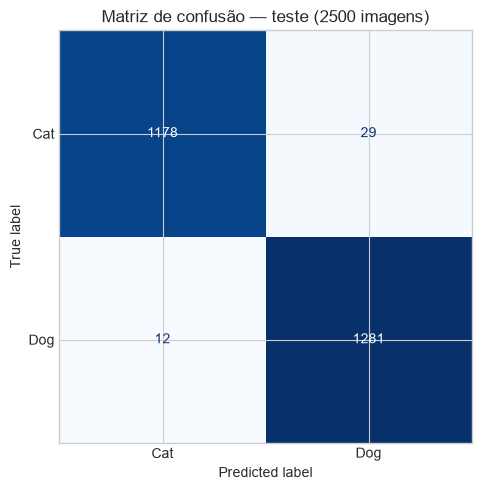

Verdadeiros negativos (gato → gato): 1178
Falsos positivos (gato → cachorro): 29
Falsos negativos (cachorro → gato): 12
Verdadeiros positivos (cachorro → cachorro): 1281


In [17]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[c.capitalize() for c in CLASS_NAMES],
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Matriz de confusão — teste ({len(y_true)} imagens)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Verdadeiros negativos (gato → gato): {tn}")
print(f"Falsos positivos (gato → cachorro): {fp}")
print(f"Falsos negativos (cachorro → gato): {fn}")
print(f"Verdadeiros positivos (cachorro → cachorro): {tp}")

### Curva ROC

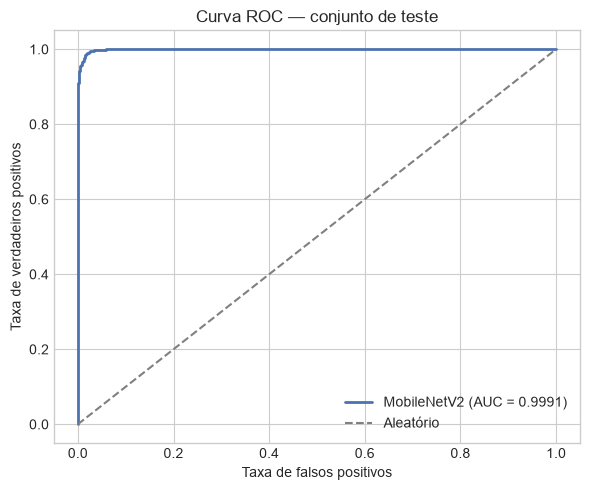

AUC-ROC: 0.9991


In [18]:
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color="#4C72B0", lw=2, label=f"MobileNetV2 (AUC = {roc_auc:.4f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Aleatório")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.set_title("Curva ROC — conjunto de teste")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "curva_roc.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"AUC-ROC: {roc_auc:.4f}")

<a id="7"></a>
## 🖼️ 7. Previsões em imagens do teste

Abaixo mostramos 12 imagens do conjunto de teste com a classe real, a previsão e a confiança do modelo. Títulos em **verde** indicam acerto; em **vermelho**, erro.

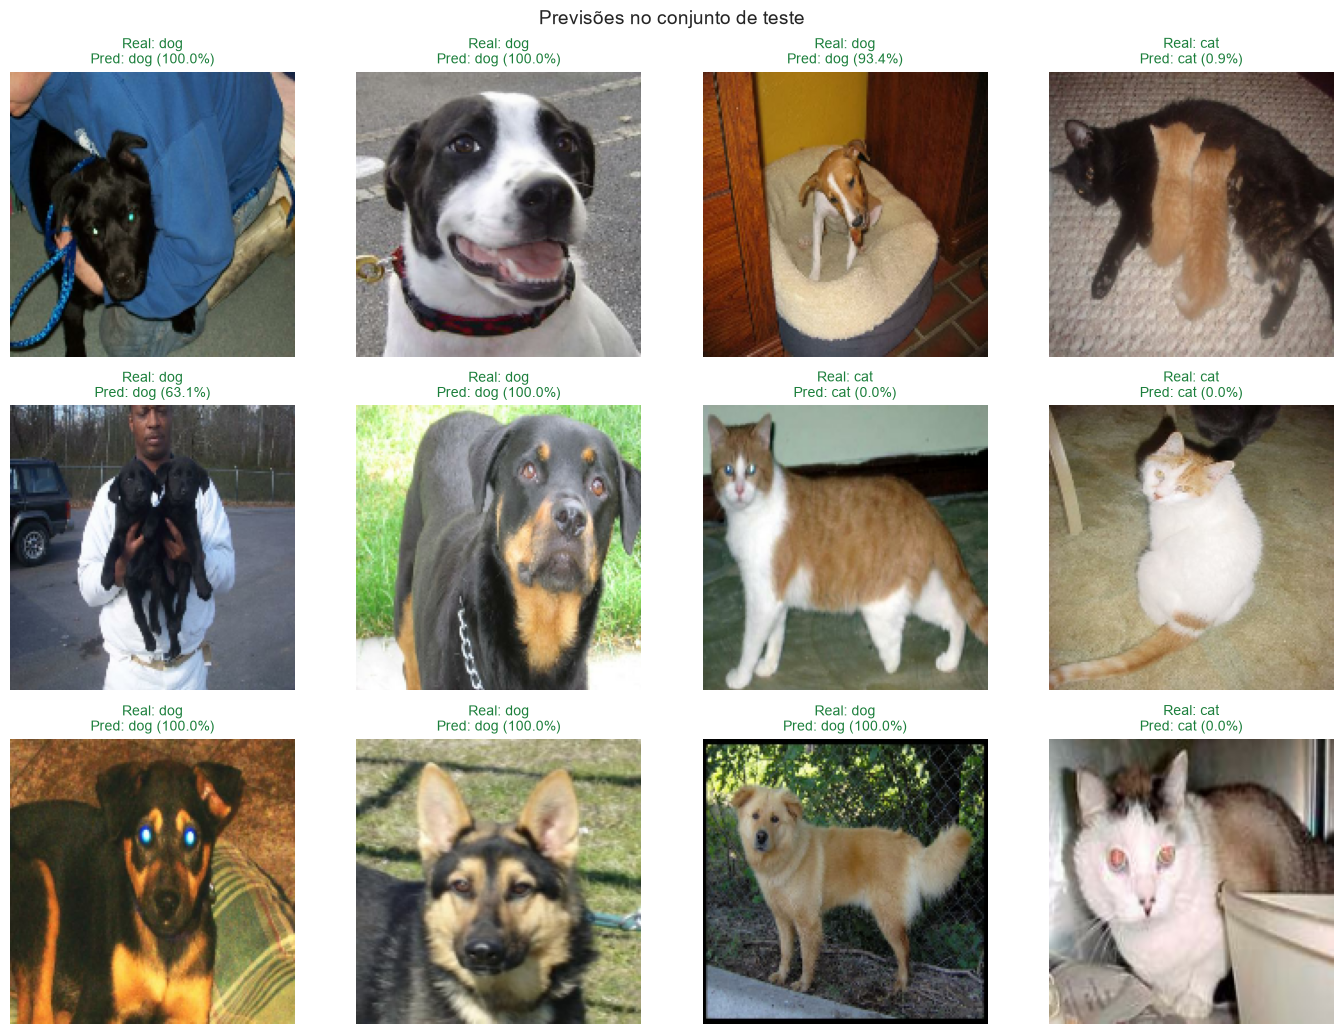

In [19]:
n_show = 12
fig, axes = plt.subplots(3, 4, figsize=(14, 10.5))

for ax, (image, label) in zip(axes.ravel(), ds_test_raw.take(n_show)):
    img_array = preprocess_input(tf.image.resize(image, IMG_SIZE).numpy())[None, ...]
    prob = float(model.predict(img_array, verbose=0)[0][0])
    pred = int(prob >= 0.5)
    true = int(label)

    ax.imshow(image.numpy().astype("uint8"))
    ax.axis("off")
    color = "#1B7F3B" if pred == true else "#C0392B"
    ax.set_title(
        f"Real: {CLASS_NAMES[true]}\nPred: {CLASS_NAMES[pred]} ({prob:.1%})",
        color=color,
        fontsize=10,
    )

fig.suptitle("Previsões no conjunto de teste", fontsize=14)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "previsoes_teste.png", dpi=150, bbox_inches="tight")
plt.show()

<a id="8"></a>
## 🔍 8. Grad-CAM: onde a rede está olhando?

O **Grad-CAM** gera um mapa de calor mostrando quais regiões da imagem mais influenciaram a decisão do modelo. É uma ferramenta de **interpretabilidade** importante: ajuda a verificar se a rede aprendeu a olhar para o animal (focinho, orelhas, olhos) e não para o fundo da foto.

A implementação usa os gradientes da saída em relação à última camada convolucional (`Conv_1`) da MobileNetV2.

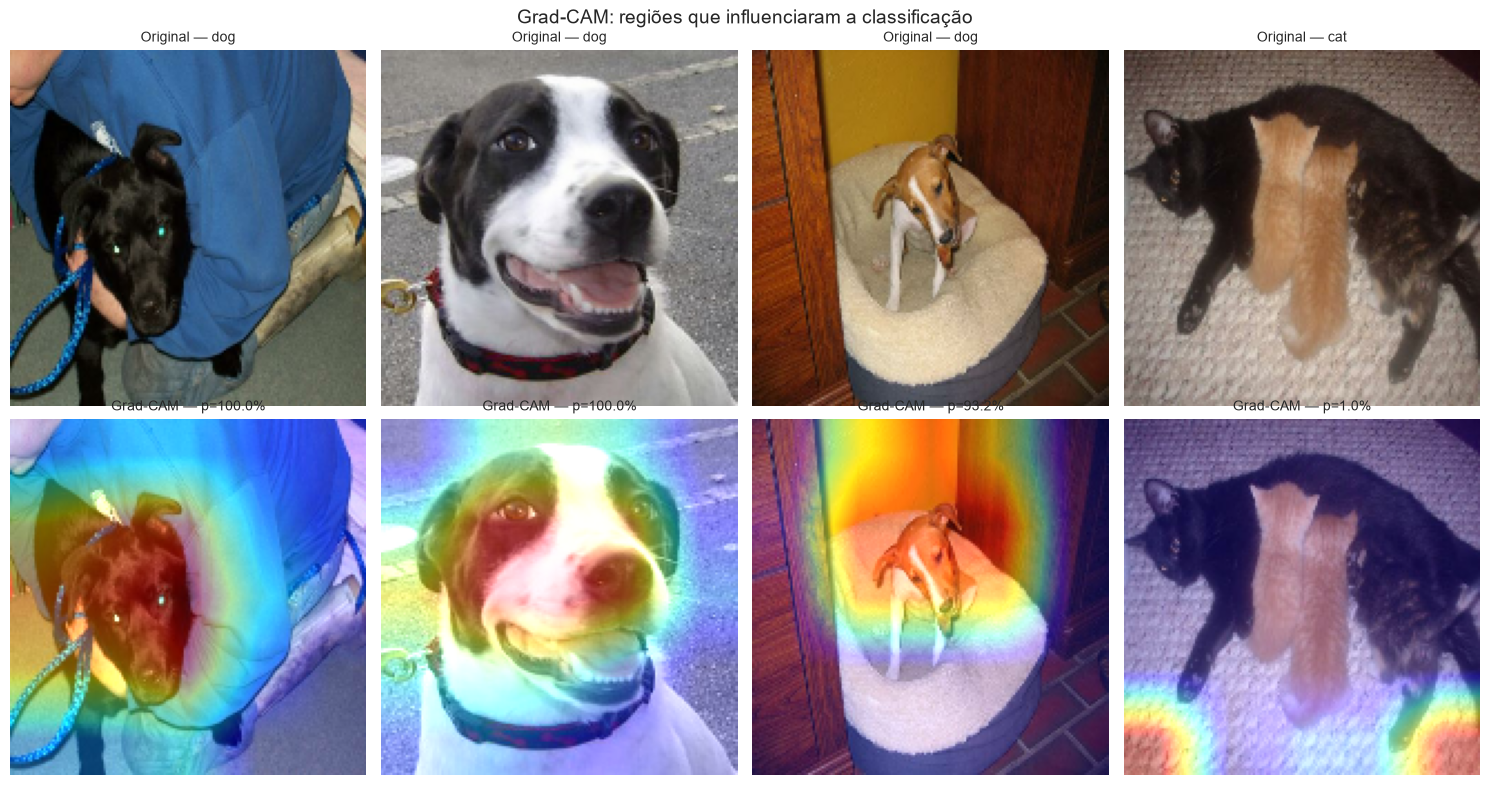

In [20]:
def make_gradcam_heatmap(img_array, model, base_model):
    grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[base_model.get_layer("Conv_1").output, base_model.output],
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = grad_model(img_array, training=False)
        pooled = tf.reduce_mean(base_outputs, axis=(1, 2))
        logits = model.get_layer("dense")(pooled)
        prob_dog = tf.sigmoid(logits)[:, 0]
        # Explica a classe prevista: P(cachorro) ou P(gato), o que for maior.
        score = tf.reduce_max(tf.stack([prob_dog, 1.0 - prob_dog]), axis=0)

    grads = tape.gradient(score, conv_outputs)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    heatmap = tf.reduce_sum(conv_outputs * weights[:, None, None, :], axis=-1)[0]
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    # O mapa tem 5x5; redimensiona para o tamanho da imagem antes de sobrepor.
    heatmap = tf.image.resize(heatmap[..., None], IMG_SIZE)[..., 0]
    return heatmap.numpy()


fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for i, (image, label) in enumerate(ds_test_raw.take(4)):
    original = tf.image.resize(image, IMG_SIZE).numpy().astype("uint8")
    img_array = preprocess_input(original.astype("float32"))[None, ...]

    heatmap = make_gradcam_heatmap(img_array, model, base_model)
    prob = float(model.predict(img_array, verbose=0)[0][0])

    jet = plt.colormaps["jet"](np.arange(256))[:, :3]
    jet_heatmap = jet[np.uint8(255 * heatmap)]
    superimposed = np.clip(jet_heatmap * 0.45 + original / 255.0, 0, 1)

    axes[0, i].imshow(original)
    axes[0, i].set_title(f"Original — {CLASS_NAMES[int(label)]}", fontsize=10)
    axes[0, i].axis("off")

    axes[1, i].imshow(superimposed)
    axes[1, i].set_title(f"Grad-CAM — p={prob:.1%}", fontsize=10)
    axes[1, i].axis("off")

fig.suptitle("Grad-CAM: regiões que influenciaram a classificação", fontsize=14)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "gradcam.png", dpi=150, bbox_inches="tight")
plt.show()

<a id="9"></a>
## 💾 9. Salvando o modelo

Salvamos o modelo em três formatos:

| Formato | Uso |
|---|---|
| `.keras` | Formato nativo do Keras 3, usado para continuar treinando ou fazer inferência em Python |
| `SavedModel` | Formato padrão do TensorFlow para servir em produção (TF Serving, por exemplo) |
| `.tflite` | Versão otimizada para dispositivos móveis e embarcados |

In [21]:
keras_path = MODELS_DIR / "cats_vs_dogs_mobilenetv2.keras"
model.save(keras_path)
print("Salvo:", keras_path, f"({keras_path.stat().st_size / 1e6:.1f} MB)")

export_dir = MODELS_DIR / "saved_model"
if export_dir.exists():
    shutil.rmtree(export_dir)
model.export(export_dir)
print("SavedModel exportado em:", export_dir)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
tflite_path = MODELS_DIR / "cats_vs_dogs_mobilenetv2.tflite"
tflite_path.write_bytes(tflite_model)
print("Salvo:", tflite_path, f"({tflite_path.stat().st_size / 1e6:.1f} MB)")

Salvo: C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\models\cats_vs_dogs_mobilenetv2.keras (21.7 MB)


INFO:tensorflow:Assets written to: C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\models\saved_model\assets


INFO:tensorflow:Assets written to: C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\models\saved_model\assets


Saved artifact at 'C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\models\saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='imagem')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2599797364816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797365776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797367312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797366544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797365200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797365584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797367504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797368272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797367888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797366736: TensorSpe

SavedModel exportado em: C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\models\saved_model


INFO:tensorflow:Assets written to: C:\Users\Will\AppData\Local\Temp\tmp8n6ecogv\assets


INFO:tensorflow:Assets written to: C:\Users\Will\AppData\Local\Temp\tmp8n6ecogv\assets


Saved artifact at 'C:\Users\Will\AppData\Local\Temp\tmp8n6ecogv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='imagem')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2599797364816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797365776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797367312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797366544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797365200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797365584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797367504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797368272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797367888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599797366736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  259979736692

Salvo: C:\Users\Will\Desktop\projetos\Treinamento de Redes Neurais com Transfer Learning\models\cats_vs_dogs_mobilenetv2.tflite (8.9 MB)


O script `src/predict.py` do repositório usa o arquivo `.keras` para classificar uma imagem qualquer:

```bash
python src/predict.py --imagem caminho/para/foto.jpg --modelo models/cats_vs_dogs_mobilenetv2.keras
```

<a id="10"></a>
## ✅ 10. Conclusão

Neste notebook aplicamos Transfer Learning em duas etapas e mostramos, na prática, por que essa técnica é tão usada:

- **Menos dados são necessários**: a base já sabe extrair características visuais do ImageNet;
- **Treinamento mais rápido**: na fase 1 treinamos apenas ~1,3 mil parâmetros da cabeça;
- **Melhor desempenho**: o fine-tuning ajusta as últimas camadas ao domínio de gatos e cachorros;
- **Interpretabilidade**: o Grad-CAM ajuda a conferir se o modelo olha para o animal, e não para o fundo;
- **Validar os dados compensa**: o zip oficial contém arquivos `.jpg` que na verdade são BMP/GIF/PSD; validar cada imagem por decodificação evitou quebras no meio do treino.

### Limitações e próximos passos

- O dataset tem imagens ruidosas e de tamanhos variados; um pipeline de limpeza poderia melhorar os resultados;
- Testar outras arquiteturas (EfficientNetB0, ResNet50) e comparar custo × acurácia;
- Usar **k-fold cross-validation** para uma estimativa mais robusta;
- Exportar o `.tflite` e testar em um app móvel;
- Substituir o dataset por **fotos próprias** (ex.: seus animais) e repetir o processo — o Transfer Learning brilha justamente quando temos poucos dados.

### Referências

- [TensorFlow — Transfer learning and fine-tuning](https://www.tensorflow.org/tutorials/images/transfer_learning)
- [MobileNetV2 — paper (Sandler et al., 2018)](https://arxiv.org/abs/1801.04381)
- [TensorFlow — tf.data](https://www.tensorflow.org/guide/data)
- [Kaggle — Dogs vs. Cats](https://www.kaggle.com/c/dogs-vs-cats)
- [TensorFlow Datasets — Cats vs Dogs](https://www.tensorflow.org/datasets/catalog/cats_vs_dogs)
- [Keras Blog — Building powerful image classification models using very little data](https://blog.keras.io/building-powerful-image-classification-models-using-very-little-data.html)
- [Grad-CAM — paper (Selvaraju et al., 2017)](https://arxiv.org/abs/1610.02391)
- [DIO — Treinamento de Redes Neurais com Transfer Learning](https://www.dio.me/)